# **Semantic search evaluation**

In this notebook we are going to do an evaluation about the semantic search strategy based on :
- Chunk size
- Overlap size
- and the n_results parameter

In [1]:
from pathlib import Path
import chromadb

In [2]:
db_path = Path(".").resolve().parent / "Collections"
client = chromadb.PersistentClient(path=db_path)

In [3]:
def get_all_documents(collection, batch_size=500):
    documents = []
    ids = []
    metadatas = []
    offset = 0

    while True:
        batch = collection.get(
            limit=batch_size,
            offset=offset,
            include=["documents", "metadatas"],
        )

        batch_ids = batch["ids"]
        batch_documents = batch["documents"] or []
        batch_metadatas = batch["metadatas"] or []

        if not batch_ids:
            break

        if not (
            len(batch_ids)
            == len(batch_documents)
            == len(batch_metadatas)
        ):
            raise ValueError(
                "Chroma returned misaligned documents, IDs, and metadata"
            )

        ids.extend(batch_ids)
        documents.extend(batch_documents)
        metadatas.extend(batch_metadatas)

        offset += len(batch_ids)

    if not documents:
        raise ValueError("The Chroma collection contains no documents")

    return {
        "documents": documents,
        "ids": ids,
        "metadatas": metadatas,
    }

In [4]:
import json
from pathlib import Path

file_path = db_path = Path(".").resolve().parent / "Retreival" / "keyword_evaluation.json"
if file_path is None:
    raise FileNotFoundError(
        "keyword_evaluation.json was not found from the current working directory"
    )

with file_path.open(encoding="utf-8") as file:
    evaluation_data = json.load(file)

queries = evaluation_data["queries"]

In [5]:
from Retreival.SemanticSearch import evaluate_strategy as semantic_evaluate_strategy
from Retreival.SemanticSearch import semanticSearch

In [10]:
def evaluate_search(
        search_function,
        method_name, 
        evaluation_queries, 
        collection_names = [
            "jurisprudence_chunk_100_overlap_40", 
            "jurisprudence_chunk_300_overlap_140", 
            "jurisprudence_chunk_500_overlap_240"
        ],
        n_results=[100, 300, 500, 700]
        ):
    results = []

    for collection_name in collection_names:
        collection = client.get_collection(name=collection_name)
        keyword_index = get_all_documents(collection)
        # Evaluate the search function on the current collection
        print(f"Indexes built for {len(keyword_index['documents'])} chunks")
        summary_semantic, per_query_semantic = semantic_evaluate_strategy(n_results, collection, search_function, method_name, evaluation_queries, keyword_index)

        res = {
            "collection_name": collection_name,
            "method_name": method_name,
            "summary": summary_semantic,
            "per_query": per_query_semantic,            
        }
        results.append(res)

    return results

## **Evaluation**

In [11]:
results_semantic = evaluate_search(semanticSearch, "Semantic", queries)

Indexes built for 103688 chunks
Indexes built for 38976 chunks
Indexes built for 23946 chunks


,Configuration,n_results,precision@2,recall@2,ndcg@2,precision@5,recall@5,ndcg@5,precision@10,recall@10,ndcg@10
0,100/40,100,0.033333,0.005556,0.040876,0.026667,0.072222,0.048401,0.013333,0.072222,0.040463
1,100/40,300,0.033333,0.066667,0.042062,0.013333,0.066667,0.042062,0.006667,0.066667,0.042062
2,100/40,500,0.033333,0.066667,0.042062,0.013333,0.066667,0.042062,0.006667,0.066667,0.042062
3,100/40,700,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,300/140,100,0.033333,0.022222,0.025790,0.026667,0.088889,0.048451,0.020000,0.094444,0.053079
5,300/140,300,0.033333,0.022222,0.040876,0.013333,0.022222,0.031285,0.013333,0.027778,0.035527
6,300/140,500,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
7,300/140,700,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
8,500/240,100,0.033333,0.033333,0.040876,0.013333,0.033333,0.040876,0.013333,0.038889,0.045767
9,500/240,300,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.006667,0.033333,0.012895


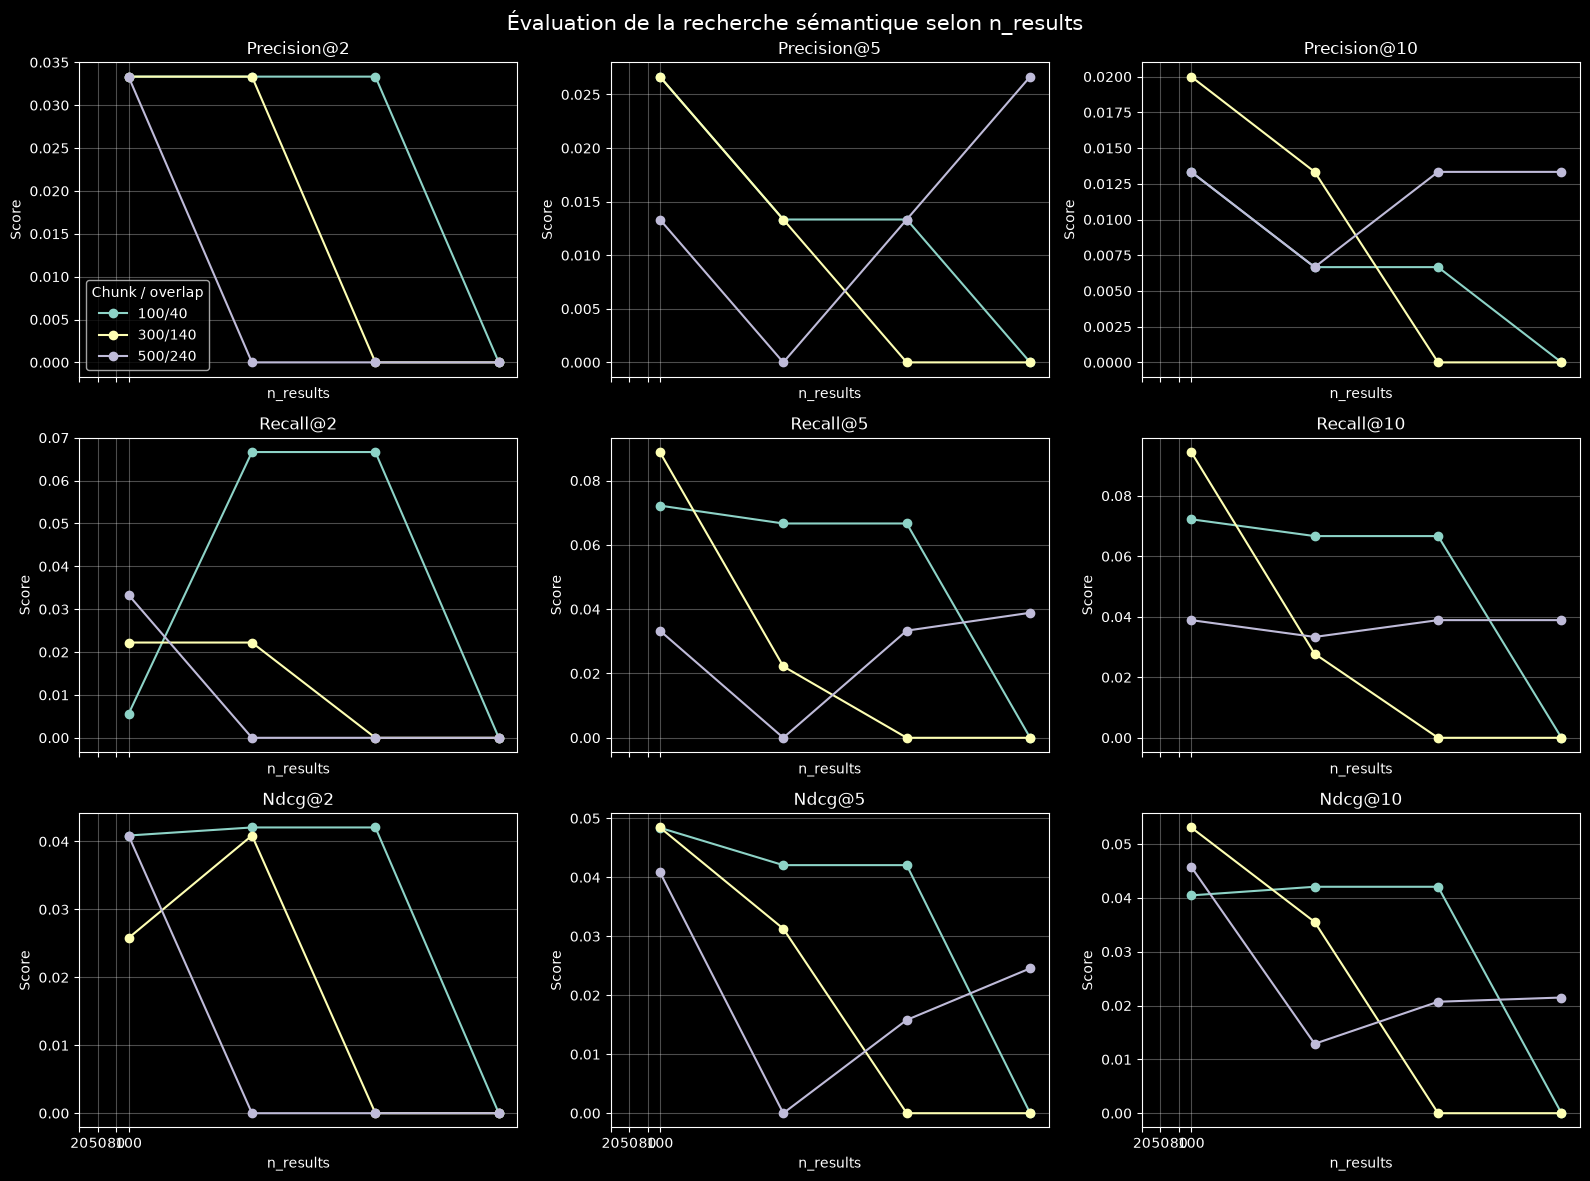

In [19]:

import matplotlib.pyplot as plt
import pandas as pd
import re

# 1. Transformer le résumé en DataFrame
rows = []

for result in results_semantic:
    collection_name = result["collection_name"]

    # Extraire la configuration : chunk size et overlap
    match = re.search(
        r"chunk_(\d+)_overlap_(\d+)",
        collection_name
    )

    config = (
        f"{match.group(1)}/{match.group(2)}"
        if match
        else collection_name
    )

    summary = result["summary"]

    for n in [100, 300, 500, 700]:
        row = {
            "Configuration": config,
            "n_results": n,
        }

        for k in [2, 5, 10]:
            for metric in ["precision", "recall", "ndcg"]:
                key = f"{metric}@{k}_{n}"
                if key in summary:
                    row[f"{metric}@{k}"] = summary[key]

        rows.append(row)

df = pd.DataFrame(rows)

# Vérifier les données utilisées pour les graphiques
display(df.sort_values(["Configuration", "n_results"]))

# 2. Tracer Precision@k, Recall@k et nDCG@k
metrics = ["precision", "recall", "ndcg"]
k_values = [2, 5, 10]

fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(16, 12),
    sharex=True
)

for i, metric in enumerate(metrics):
    for j, k in enumerate(k_values):
        ax = axes[i, j]
        column = f"{metric}@{k}"

        for config, group in df.groupby("Configuration"):
            group = group.sort_values("n_results")

            if column in group.columns:
                ax.plot(
                    group["n_results"],
                    group[column],
                    marker="o",
                    label=config
                )

        ax.set_title(f"{metric.capitalize()}@{k}")
        ax.set_xlabel("n_results")
        ax.set_ylabel("Score")
        ax.set_xticks([20, 50, 80, 100])
        ax.grid(True, alpha=0.3)

        if i == 0 and j == 0:
            ax.legend(title="Chunk / overlap")

fig.suptitle(
    "Évaluation de la recherche sémantique selon n_results",
    fontsize=15
)
plt.tight_layout()
plt.show()


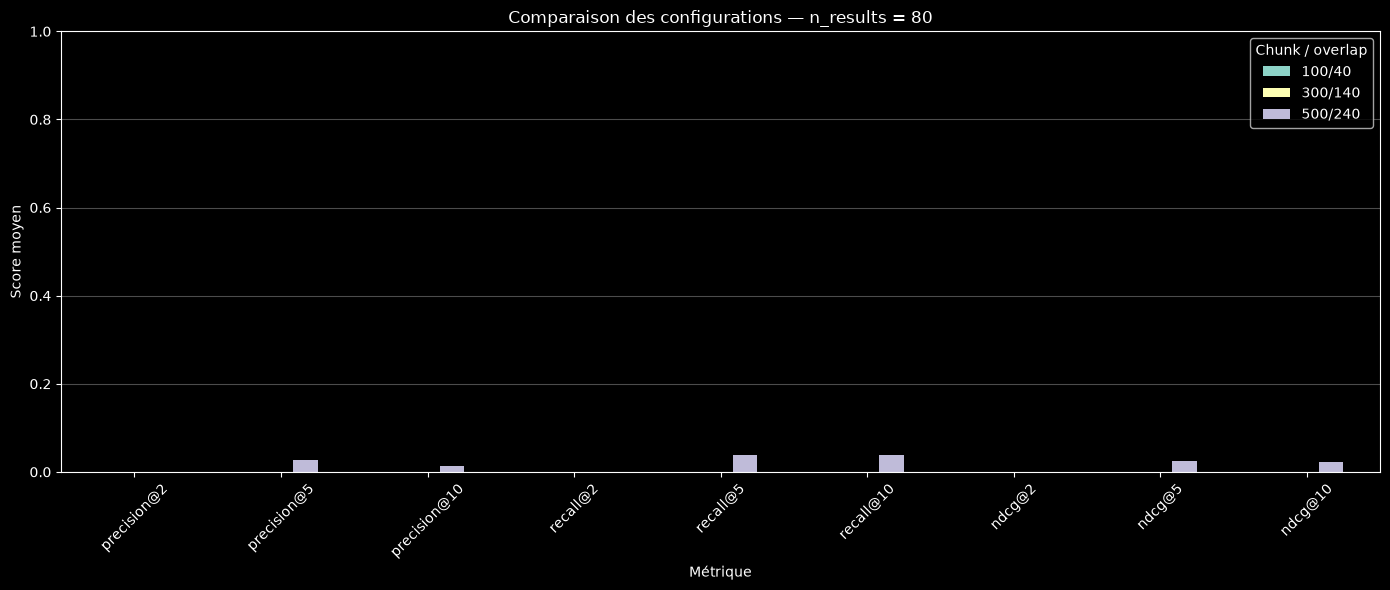

In [26]:

metrics_at_100 = [
    "precision@2", "precision@5", "precision@10",
    "recall@2", "recall@5", "recall@10",
    "ndcg@2", "ndcg@5", "ndcg@10",
]

df_100 = df[df["n_results"] == 700].set_index("Configuration")

ax = df_100[metrics_at_100].T.plot(
    kind="bar",
    figsize=(14, 6)
)

ax.set_title("Comparaison des configurations — n_results = 80")
ax.set_ylabel("Score moyen")
ax.set_xlabel("Métrique")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Chunk / overlap")
plt.tight_layout()
plt.show()
